In [4]:
#lecturaRostros

import cv2
import numpy as np
import os

imagenes = []

for archivo in os.listdir("caras"):

    ruta = os.path.join(
        "caras",
        archivo
    )

    img = cv2.imread(
        ruta,
        cv2.IMREAD_GRAYSCALE
    )

    img = cv2.resize(
        img,
        (100,100)
    )

    vector = img.flatten()

    imagenes.append(vector)

X = np.array(
    imagenes,
    dtype=np.float32
)

print(X.shape)
mean, eigenvectors = cv2.PCACompute(
    X,
    mean=None,
    maxComponents=50
)


(200, 10000)


200 rostros guardados


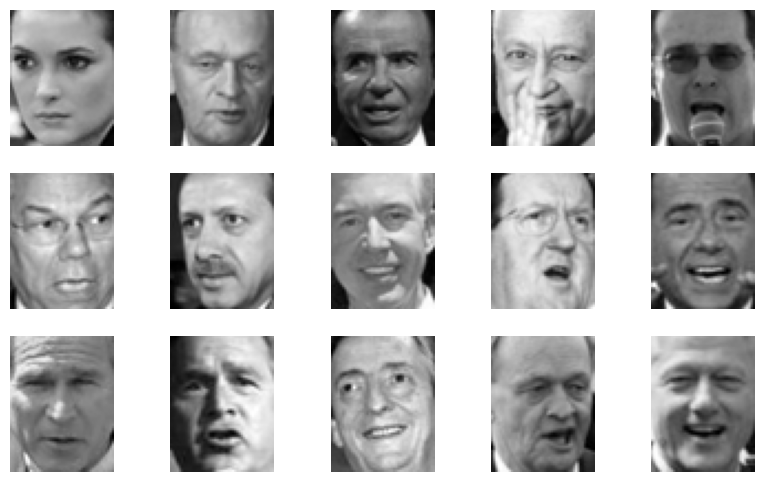

In [2]:
#obtenerRostros1

from sklearn.datasets import fetch_lfw_people
import matplotlib.pyplot as plt
import os
from PIL import Image
import numpy as np

# Descargar dataset
lfw = fetch_lfw_people(
    min_faces_per_person= 20,
    resize=0.5
)
"""
lfw = fetch_lfw_people(
    min_faces_per_person=20,
    resize=0.5
)
"""
# Crear carpeta
os.makedirs("caras", exist_ok=True)

# Tomar 200 imágenes
imagenes = lfw.images[:200]

# Guardar imágenes
for i, img in enumerate(imagenes):
    img = (img * 255).astype(np.uint8)
    imagen = Image.fromarray(img)
    imagen.save(f"caras/{i+1}.jpg")

print("200 rostros guardados")

#visualizar
fig, axes = plt.subplots(3, 5, figsize=(10,6))

for ax, img in zip(axes.ravel(), imagenes[:15]):
    ax.imshow(img, cmap="gray")
    ax.axis("off")

plt.show()



In [3]:
!zip -r caras.zip caras/

  adding: caras/ (stored 0%)
  adding: caras/98.jpg (stored 0%)
  adding: caras/75.jpg (stored 0%)
  adding: caras/67.jpg (stored 0%)
  adding: caras/172.jpg (stored 0%)
  adding: caras/72.jpg (stored 0%)
  adding: caras/142.jpg (stored 0%)
  adding: caras/61.jpg (stored 0%)
  adding: caras/170.jpg (stored 0%)
  adding: caras/34.jpg (stored 0%)
  adding: caras/73.jpg (stored 0%)
  adding: caras/174.jpg (stored 0%)
  adding: caras/180.jpg (stored 0%)
  adding: caras/165.jpg (stored 0%)
  adding: caras/113.jpg (stored 0%)
  adding: caras/122.jpg (stored 0%)
  adding: caras/191.jpg (stored 0%)
  adding: caras/185.jpg (stored 0%)
  adding: caras/96.jpg (stored 0%)
  adding: caras/196.jpg (stored 0%)
  adding: caras/198.jpg (stored 0%)
  adding: caras/62.jpg (stored 0%)
  adding: caras/124.jpg (stored 0%)
  adding: caras/193.jpg (stored 0%)
  adding: caras/119.jpg (stored 0%)
  adding: caras/82.jpg (stored 0%)
  adding: caras/164.jpg (stored 0%)
  adding: caras/31.jpg (stored 0%)
  adding: 

obtenerRostros2

In [8]:
!pip install icrawler

In [9]:
#pip install icrawler

from icrawler.builtin import GoogleImageCrawler

crawler = GoogleImageCrawler(
    storage={"root_dir": "caras2"}
)

crawler.crawl(
    keyword="human face portrait",
    max_num=200
)



Exception in thread parser-001:
Traceback (most recent call last):
  File "/usr/lib/python3.12/threading.py", line 1075, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.12/threading.py", line 1012, in run
    self._target(*self._args, **self._kwargs)
  File "/usr/local/lib/python3.12/dist-packages/icrawler/parser.py", line 93, in worker_exec
    for task in self.parse(response, **kwargs):
                ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
TypeError: 'NoneType' object is not iterable


obtenerRostros3 - ejecutar en local

In [ ]:
import cv2
import os

os.makedirs("caras2", exist_ok=True)

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades +
    "haarcascade_frontalface_default.xml"
)

cap = cv2.VideoCapture(0)
contador = 1
while contador <= 200:

    ret, frame = cap.read()

    gray = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2GRAY
    )

    faces = face_cascade.detectMultiScale(
        gray,
        1.3,
        5
    )

    for (x,y,w,h) in faces:

        rostro = gray[y:y+h, x:x+w]

        rostro = cv2.resize(
            rostro,
            (100,100)
        )

        cv2.imwrite(
            f"caras2/{contador}.jpg",
            rostro
        )

        contador += 1

        cv2.rectangle(
            frame,
            (x,y),
            (x+w,y+h),
            (255,0,0),
            2
        )

        print(f"Guardado {contador}")

    cv2.imshow("Captura", frame)

    if cv2.waitKey(1) == 27:
        break

cap.release()
cv2.destroyAllWindows()


obtenerRostros4

In [10]:
import requests

for i in range(200):

    url = "https://thispersondoesnotexist.com/"

    img = requests.get(url).content

    with open(f"caras3/{i}.jpg", "wb") as f:

        f.write(img)


FileNotFoundError: [Errno 2] No such file or directory: 'caras3/0.jpg'

obtenerRostros5

In [14]:
import requests
import time
import os

os.makedirs('caras5', exist_ok=True)

for i in range(200):

    img = requests.get(
        "https://thispersondoesnotexist.com/"
    ).content

    with open(f"caras5/{i}.jpg", "wb") as f:

        f.write(img)

    time.sleep(2)


In [15]:
!zip -r caras3.zip caras5/

  adding: caras5/ (stored 0%)
  adding: caras5/98.jpg (deflated 0%)
  adding: caras5/75.jpg (deflated 0%)
  adding: caras5/67.jpg (deflated 0%)
  adding: caras5/172.jpg (deflated 0%)
  adding: caras5/72.jpg (deflated 0%)
  adding: caras5/142.jpg (deflated 0%)
  adding: caras5/61.jpg (deflated 0%)
  adding: caras5/170.jpg (deflated 0%)
  adding: caras5/34.jpg (deflated 0%)
  adding: caras5/73.jpg (deflated 0%)
  adding: caras5/174.jpg (deflated 0%)
  adding: caras5/180.jpg (deflated 0%)
  adding: caras5/165.jpg (deflated 0%)
  adding: caras5/113.jpg (deflated 0%)
  adding: caras5/122.jpg (deflated 0%)
  adding: caras5/191.jpg (deflated 0%)
  adding: caras5/185.jpg (deflated 0%)
  adding: caras5/96.jpg (deflated 0%)
  adding: caras5/196.jpg (deflated 0%)
  adding: caras5/198.jpg (deflated 0%)
  adding: caras5/62.jpg (deflated 0%)
  adding: caras5/124.jpg (deflated 0%)
  adding: caras5/193.jpg (deflated 0%)
  adding: caras5/119.jpg (deflated 0%)
  adding: caras5/82.jpg (deflated 0%)
  add